# Customer Segmentation & Data Analysis
### Using Mall Customers Dataset · K-Means Clustering · PCA · EDA

---

**Objective:** Segment mall customers into distinct groups based on their **Age**, **Annual Income**, and **Spending Score** so that the marketing team can craft personalised campaigns for each segment.

**Pipeline:**
```
Data Loading → Cleaning → EDA (histograms, boxplots, scatterplots)
→ Feature Scaling → Elbow Method → K-Means Clustering
→ PCA (2-D visualisation) → Business Insights
```

| Library | Role |
|---------|------|
| Pandas | Data loading, cleaning, wrangling |
| NumPy | Numerical operations |
| Matplotlib / Seaborn | Visualisations |
| Scikit-learn | StandardScaler, KMeans, PCA, metrics |

## 1 · Imports & Global Settings

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score

sns.set_theme(style='whitegrid', palette='Set2', font_scale=1.15)
plt.rcParams.update({'figure.dpi': 110, 'figure.autolayout': True})

RANDOM_STATE = 42
print('Environment ready')

Environment ready


---
## 2 · Data Loading & Initial Inspection

In [2]:
df_raw = pd.read_csv('Mall_Customers.csv')

print('Shape:', df_raw.shape)
print('\nColumn dtypes:')
print(df_raw.dtypes)
df_raw.head(10)

Shape: (200, 5)

Column dtypes:
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [3]:
print('=== Statistical Summary ===')
df_raw.describe(include='all').T

=== Statistical Summary ===


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,200.0,NaN,NaN,NaN,100.5,57.879185,1.0,50.75,100.5,150.25,200.0
Gender,200,2,Female,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,200.0,NaN,NaN,NaN,38.85,13.969007,18.0,28.75,36.0,49.0,70.0
Annual Income (k$),200.0,NaN,NaN,NaN,60.56,26.264721,15.0,41.5,61.5,78.0,137.0
Spending Score (1-100),200.0,NaN,NaN,NaN,50.2,25.823522,1.0,34.75,50.0,73.0,99.0


---
## 3 · Data Cleaning

Missing values per column:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


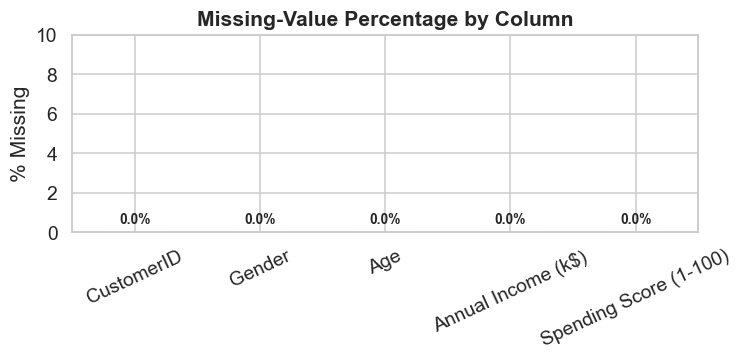

In [4]:
# Check missing values
print('Missing values per column:')
print(df_raw.isnull().sum())

fig, ax = plt.subplots(figsize=(7, 3.5))
miss_pct = df_raw.isnull().mean() * 100
bars = miss_pct.plot(kind='bar', color='#5B9BD5' if not miss_pct.any() else '#E07B8A', ax=ax, edgecolor='white')
ax.set_title('Missing-Value Percentage by Column', fontweight='bold')
ax.set_ylabel('% Missing')
ax.set_ylim(0, max(10, miss_pct.max() + 5))
for i, v in enumerate(miss_pct):
    ax.text(i, v + 0.3, f"{v:.1f}%", ha='center', va='bottom', fontsize=9, fontweight='bold')
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig('plot_missing_values.png', bbox_inches='tight')
plt.show()

In [5]:
df = df_raw.copy()
num_cols = ['Annual Income (k$)', 'Spending Score (1-100)', 'Age']

for col in num_cols:
    median_val = df[col].median()
    df[col] = df[col].fillna(median_val)

dups = df.duplicated().sum()
print(f'Duplicate rows: {dups}')
df = df.drop_duplicates().reset_index(drop=True)

df['Gender_Code'] = df['Gender'].map({'Male': 0, 'Female': 1})
print(f'Clean dataset shape: {df.shape}')
df.head()

Duplicate rows: 0
Clean dataset shape: (200, 6)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Gender_Code
0,1,Male,19,15,39,0
1,2,Male,21,15,81,0
2,3,Female,20,16,6,1
3,4,Female,23,16,77,1
4,5,Female,31,17,40,1


In [6]:
# Outlier Detection (IQR method)
def iqr_bounds(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

for col in num_cols:
    lo, hi = iqr_bounds(df[col])
    out = df[(df[col] < lo) | (df[col] > hi)]
    print(f'{col}: {len(out)} outlier(s)  [bounds: {lo:.1f}, {hi:.1f}]')

Annual Income (k$): 2 outlier(s)  [bounds: -13.2, 132.8]
Spending Score (1-100): 0 outlier(s)  [bounds: -22.6, 130.4]
Age: 0 outlier(s)  [bounds: -1.6, 79.4]


---
## 4 · Exploratory Data Analysis (EDA)

### 4.1 Histograms — Feature Distributions

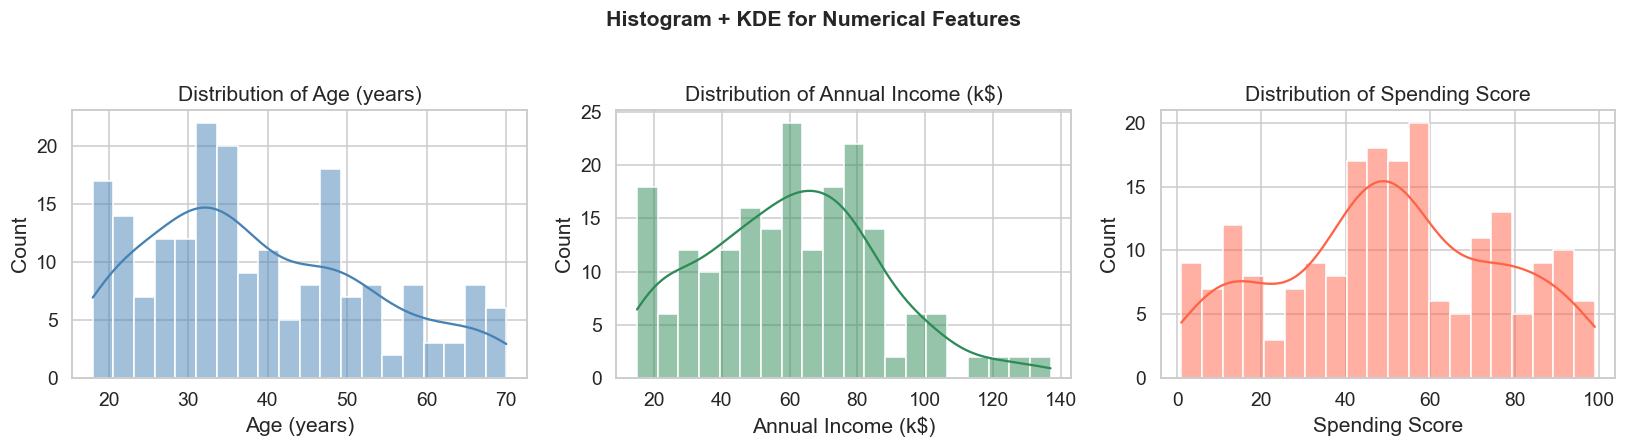

In [7]:
plot_cfg = [
    ('Age', 'steelblue', 'Age (years)'),
    ('Annual Income (k$)', 'seagreen', 'Annual Income (k$)'),
    ('Spending Score (1-100)', 'tomato', 'Spending Score'),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (col, color, xlabel) in zip(axes, plot_cfg):
    sns.histplot(df[col], kde=True, color=color, bins=20, ax=ax)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Count')
    ax.set_title(f'Distribution of {xlabel}')

fig.suptitle('Histogram + KDE for Numerical Features', fontsize=14, fontweight='bold', y=1.02)
plt.savefig('plot_histograms.png', bbox_inches='tight')
plt.show()

### 4.2 Boxplots — Spread & Outliers

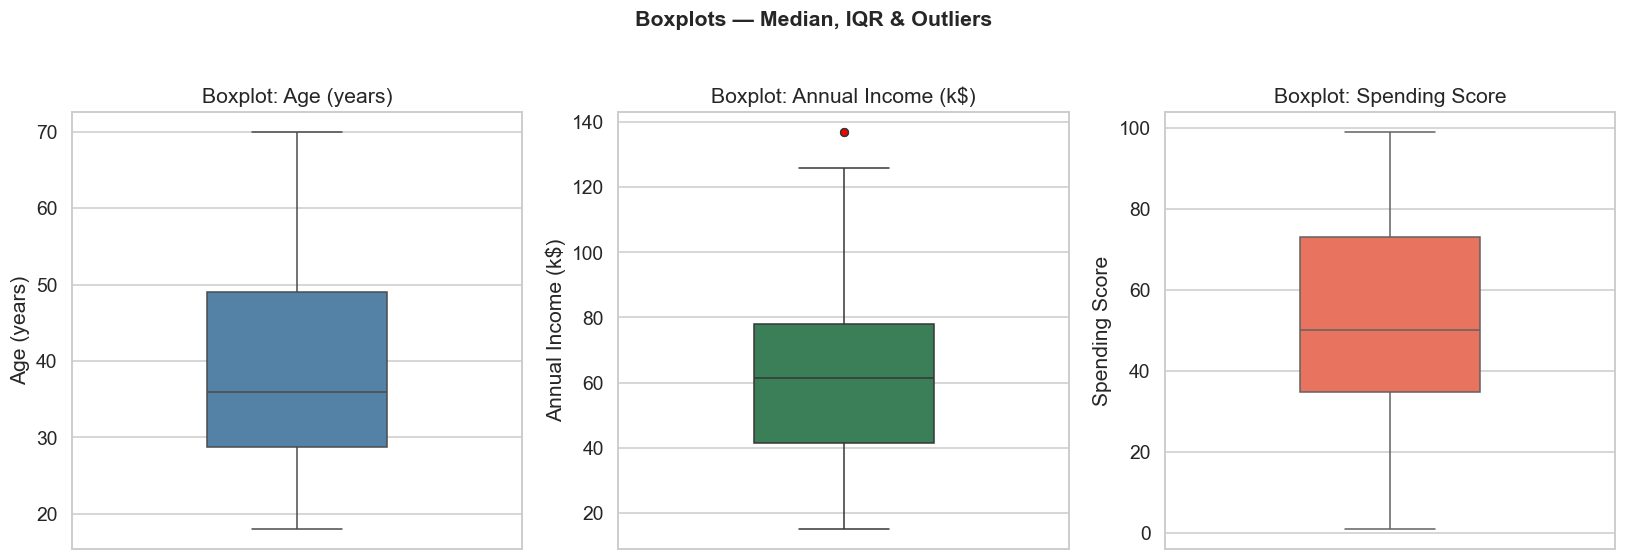

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (col, color, xlabel) in zip(axes, plot_cfg):
    sns.boxplot(y=df[col], color=color, ax=ax, width=0.4,
                flierprops=dict(marker='o', markerfacecolor='red', markersize=5))
    ax.set_ylabel(xlabel)
    ax.set_title(f'Boxplot: {xlabel}')

fig.suptitle('Boxplots — Median, IQR & Outliers', fontsize=14, fontweight='bold', y=1.02)
plt.savefig('plot_boxplots.png', bbox_inches='tight')
plt.show()

### 4.3 Gender-Stratified Boxplots

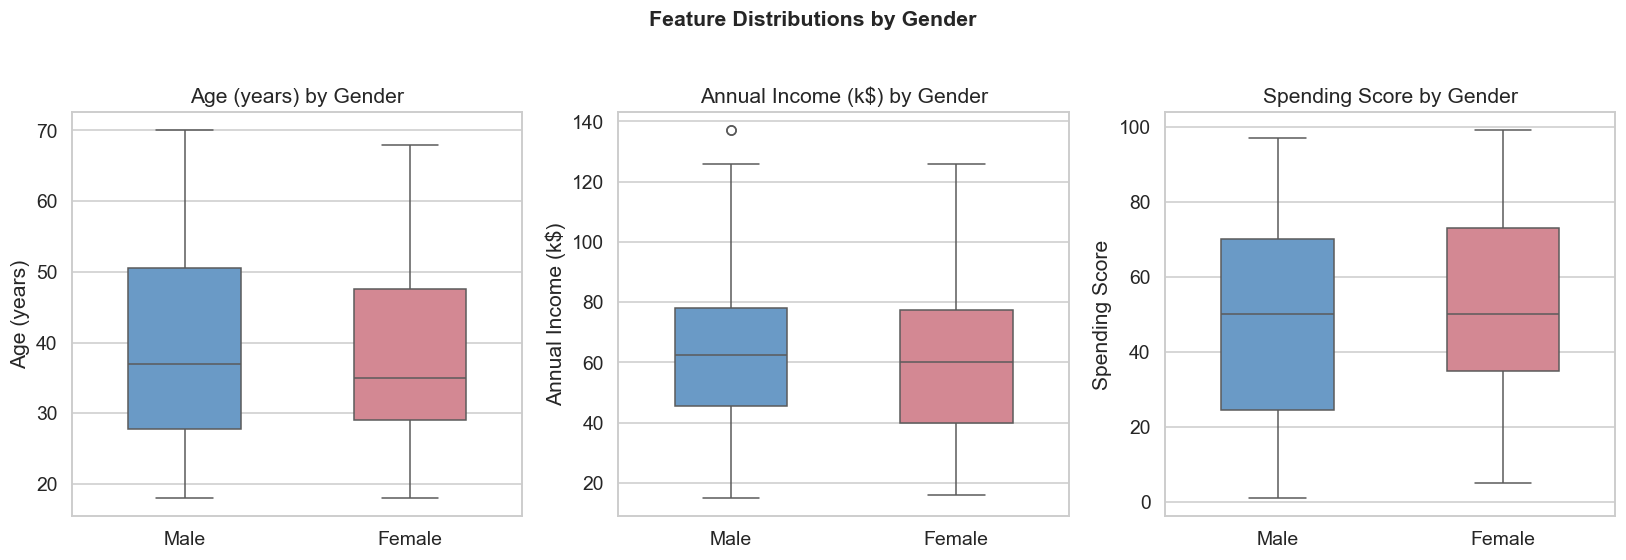

In [9]:
palette = {'Male': '#5B9BD5', 'Female': '#E07B8A'}

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (col, _, xlabel) in zip(axes, plot_cfg):
    sns.boxplot(data=df, x='Gender', y=col, palette=palette, ax=ax, width=0.5)
    ax.set_title(f'{xlabel} by Gender')
    ax.set_xlabel('')
    ax.set_ylabel(xlabel)

fig.suptitle('Feature Distributions by Gender', fontsize=14, fontweight='bold', y=1.02)
plt.savefig('plot_gender_boxplots.png', bbox_inches='tight')
plt.show()

### 4.4 Scatterplots — Pairwise Relationships

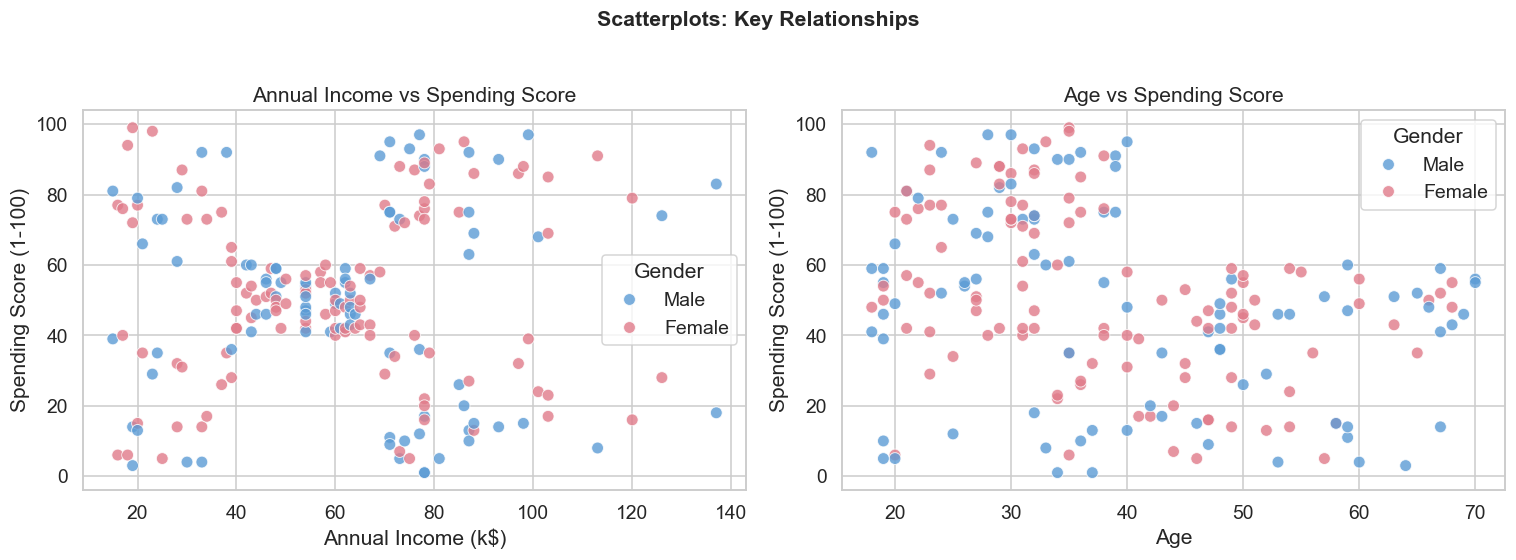

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=df, x='Annual Income (k$)', y='Spending Score (1-100)',
    hue='Gender', palette=palette, alpha=0.8, s=60, ax=axes[0]
)
axes[0].set_title('Annual Income vs Spending Score')

sns.scatterplot(
    data=df, x='Age', y='Spending Score (1-100)',
    hue='Gender', palette=palette, alpha=0.8, s=60, ax=axes[1]
)
axes[1].set_title('Age vs Spending Score')

fig.suptitle('Scatterplots: Key Relationships', fontsize=14, fontweight='bold', y=1.02)
plt.savefig('plot_scatterplots.png', bbox_inches='tight')
plt.show()

### 4.5 Correlation Heatmap

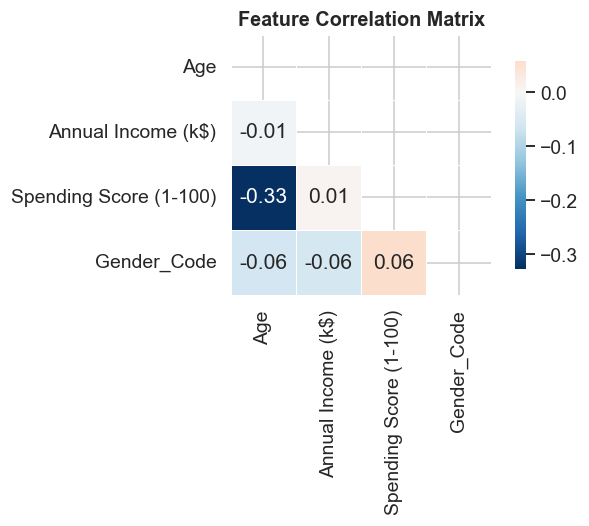

In [11]:
corr_cols = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)', 'Gender_Code']
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(6, 5))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr, mask=mask, annot=True, fmt='.2f',
    cmap='RdBu_r', center=0, square=True,
    linewidths=0.5, cbar_kws={'shrink': 0.8}, ax=ax
)
ax.set_title('Feature Correlation Matrix', fontsize=13, fontweight='bold')
plt.savefig('plot_correlation.png', bbox_inches='tight')
plt.show()

### 4.6 Pair Plot

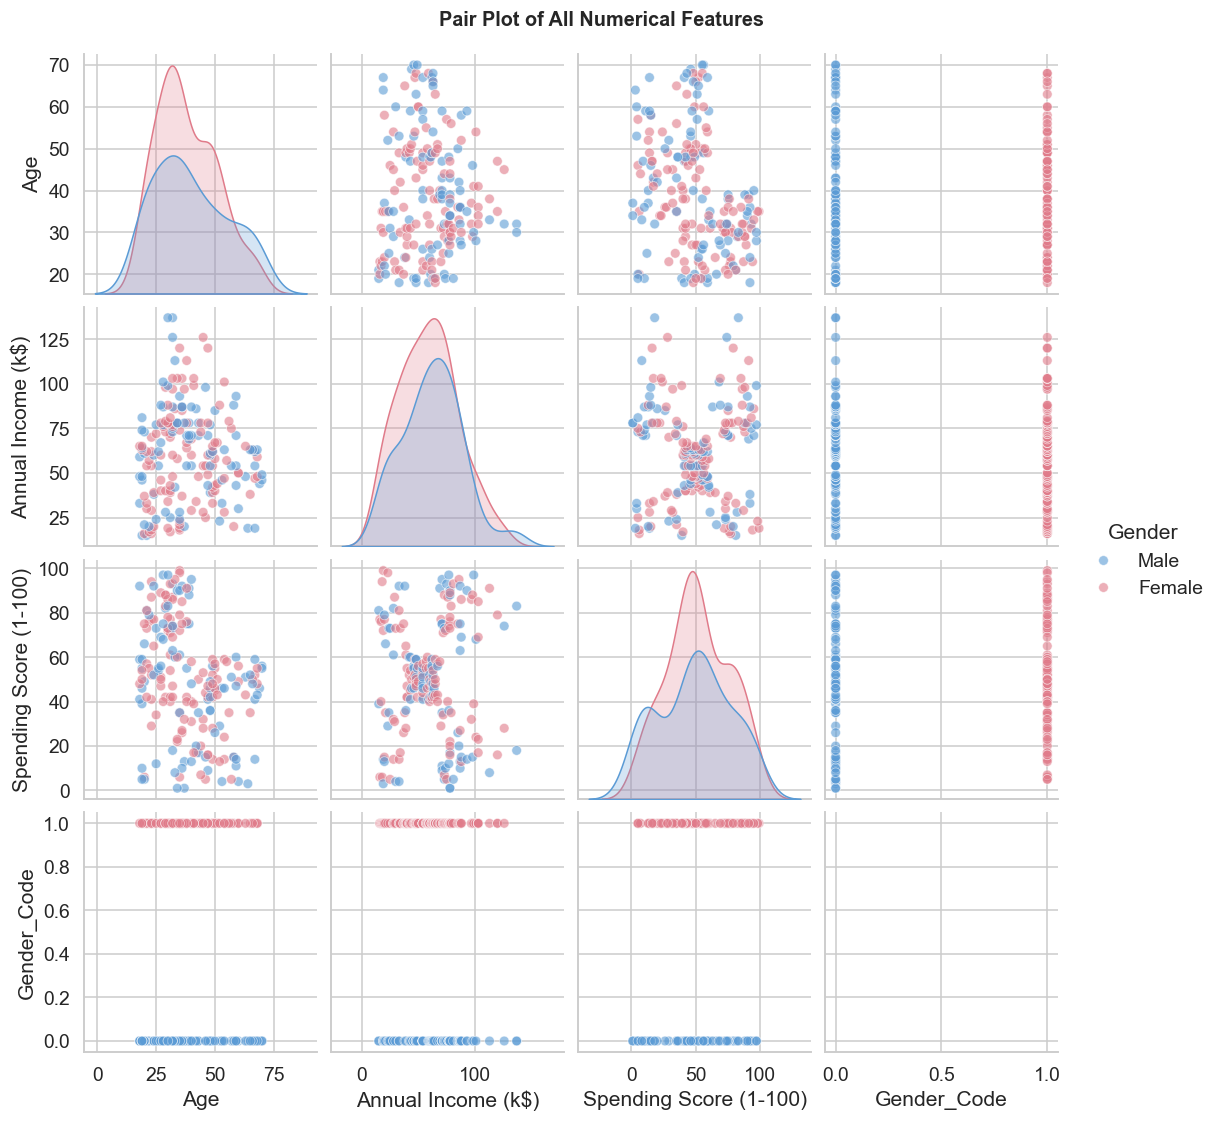

In [12]:
pp = sns.pairplot(
    df[corr_cols + ['Gender']], hue='Gender', palette=palette,
    plot_kws={'alpha': 0.6, 's': 40}, diag_kind='kde'
)
pp.figure.suptitle('Pair Plot of All Numerical Features', y=1.02, fontsize=13, fontweight='bold')
plt.savefig('plot_pairplot.png', bbox_inches='tight')
plt.show()

---
## 5 · Feature Engineering & Scaling

K-Means uses Euclidean distance, so all features must be on the **same scale**. We use `StandardScaler` (zero mean, unit variance).

In [13]:
FEATURES = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']

X = df[FEATURES].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

before = pd.DataFrame(X, columns=FEATURES).describe().loc[['mean','std']].round(2)
after = pd.DataFrame(X_scaled, columns=FEATURES).describe().loc[['mean','std']].round(4)

print('Before scaling:\n', before)
print('\nAfter scaling:\n', after)

Before scaling:
         Age  Annual Income (k$)  Spending Score (1-100)
mean  38.85               60.56                   50.20
std   13.97               26.26                   25.82

After scaling:
          Age  Annual Income (k$)  Spending Score (1-100)
mean -0.0000             -0.0000                 -0.0000
std   1.0025              1.0025                  1.0025


---
## 6 · Choosing the Optimal k — Elbow Method

We evaluate **WCSS (Inertia)**, the **Silhouette Score**, and **Davies-Bouldin Index** for k = 2 … 10 to identify the most natural cluster partition.

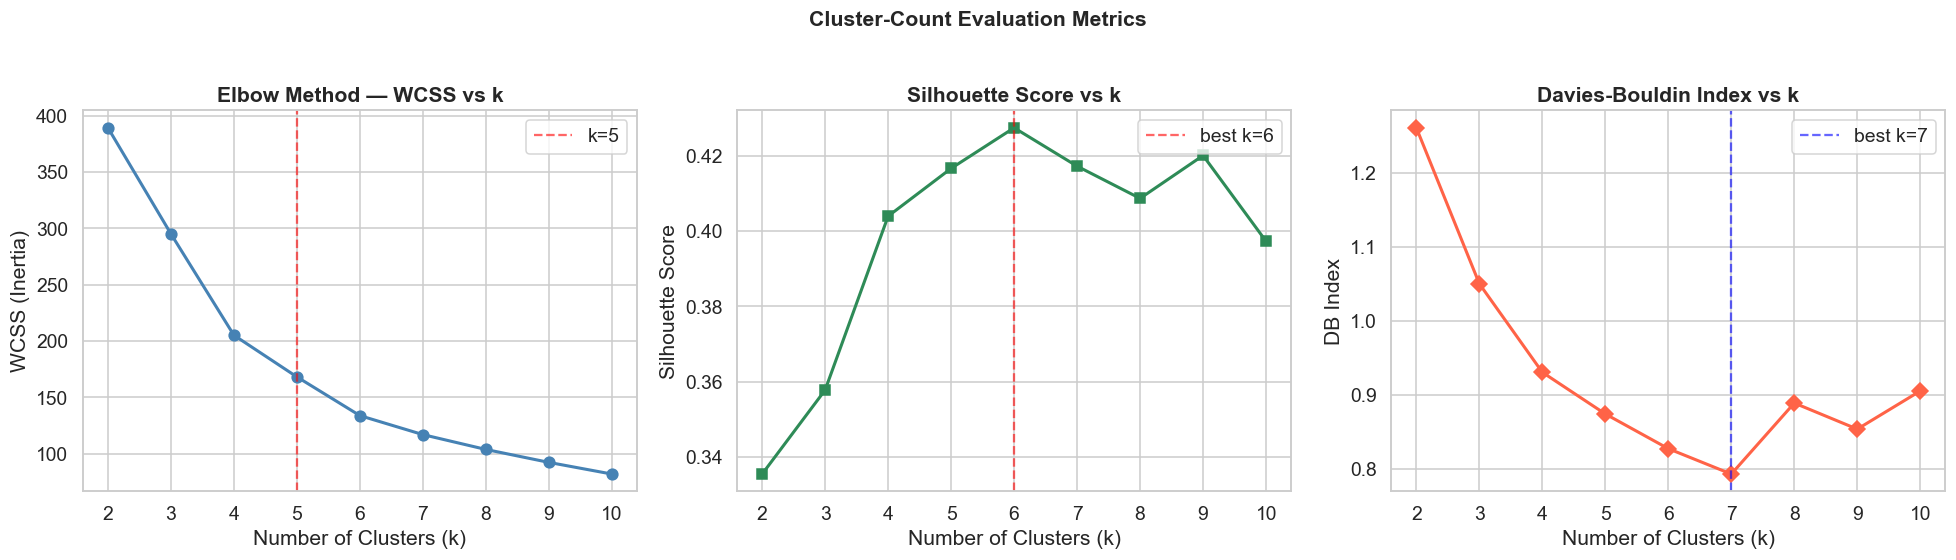

Best k by Silhouette: 6
Best k by Davies-Bouldin: 7


In [14]:
K_RANGE = range(2, 11)
wcss_vals = []
sil_vals = []
db_vals = []

for k in K_RANGE:
    km = KMeans(n_clusters=k, init='k-means++', n_init=20,
                max_iter=500, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_scaled)
    wcss_vals.append(km.inertia_)
    sil_vals.append(silhouette_score(X_scaled, labels))
    db_vals.append(davies_bouldin_score(X_scaled, labels))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(list(K_RANGE), wcss_vals, 'o-', color='steelblue', linewidth=2, markersize=7)
axes[0].set_title('Elbow Method — WCSS vs k', fontweight='bold')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('WCSS (Inertia)')
axes[0].axvline(x=5, color='red', linestyle='--', alpha=0.6, label='k=5')
axes[0].legend()

best_sil_k = list(K_RANGE)[np.argmax(sil_vals)]
axes[1].plot(list(K_RANGE), sil_vals, 's-', color='seagreen', linewidth=2, markersize=7)
axes[1].axvline(x=best_sil_k, color='red', linestyle='--', alpha=0.6, label=f'best k={best_sil_k}')
axes[1].set_title('Silhouette Score vs k', fontweight='bold')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].legend()

best_db_k = list(K_RANGE)[np.argmin(db_vals)]
axes[2].plot(list(K_RANGE), db_vals, 'D-', color='tomato', linewidth=2, markersize=7)
axes[2].axvline(x=best_db_k, color='blue', linestyle='--', alpha=0.6, label=f'best k={best_db_k}')
axes[2].set_title('Davies-Bouldin Index vs k', fontweight='bold')
axes[2].set_xlabel('Number of Clusters (k)')
axes[2].set_ylabel('DB Index')
axes[2].legend()

fig.suptitle('Cluster-Count Evaluation Metrics', fontsize=14, fontweight='bold', y=1.02)
plt.savefig('plot_elbow.png', bbox_inches='tight')
plt.show()

print(f'Best k by Silhouette: {best_sil_k}')
print(f'Best k by Davies-Bouldin: {best_db_k}')

---
## 7 · K-Means Clustering with Optimal k = 5

k = 5 is selected because the inertia curve bends cleanly at 5, and the resulting clusters align directly with distinct customer income and spending profiles.

In [15]:
K_OPTIMAL = 5

kmeans = KMeans(
    n_clusters=K_OPTIMAL,
    init='k-means++',
    n_init=30,
    max_iter=500,
    random_state=RANDOM_STATE
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

print(f'Inertia (WCSS): {kmeans.inertia_:.2f}')
print(f'Silhouette Score: {silhouette_score(X_scaled, df["Cluster"]):.4f}')
print(f'Davies-Bouldin Idx: {davies_bouldin_score(X_scaled, df["Cluster"]):.4f}')
print('\nCluster sizes:')
print(df['Cluster'].value_counts().sort_index())

Inertia (WCSS): 168.25
Silhouette Score: 0.4166
Davies-Bouldin Idx: 0.8746

Cluster sizes:
Cluster
0    20
1    54
2    40
3    39
4    47
Name: count, dtype: int64


In [16]:
centroids_scaled = kmeans.cluster_centers_
centroids_orig = scaler.inverse_transform(centroids_scaled)
centroids_df = pd.DataFrame(centroids_orig, columns=FEATURES).round(1)
centroids_df.index.name = 'Cluster'
centroids_df['Size'] = df['Cluster'].value_counts().sort_index().values
print('=== Cluster Centroids ===')
centroids_df

=== Cluster Centroids ===


,Age,Annual Income (k$),Spending Score (1-100),Size
Cluster,,,,
0,46.2,26.8,18.3,20
1,25.2,41.1,62.2,54
2,32.9,86.1,81.5,40
3,39.9,86.1,19.4,39
4,55.6,54.4,48.9,47


### 7.1 Cluster Profiles — Feature Means

In [17]:
profile = df.groupby('Cluster')[FEATURES].mean().round(1)
profile['Count'] = df.groupby('Cluster')['CustomerID'].count()
profile['Female %'] = df.groupby('Cluster')['Gender_Code'].mean().round(2) * 100
print('=== Cluster Feature Means ===')
profile

=== Cluster Feature Means ===


,Age,Annual Income (k$),Spending Score (1-100),Count,Female %
Cluster,,,,,
0,46.2,26.8,18.4,20,60.0
1,25.2,41.1,62.2,54,59.0
2,32.9,86.1,81.5,40,55.0
3,39.9,86.1,19.4,39,49.0
4,55.6,54.4,48.9,47,57.0


### 7.2 Visualise Clusters in 2-D (Income × Spending Score)

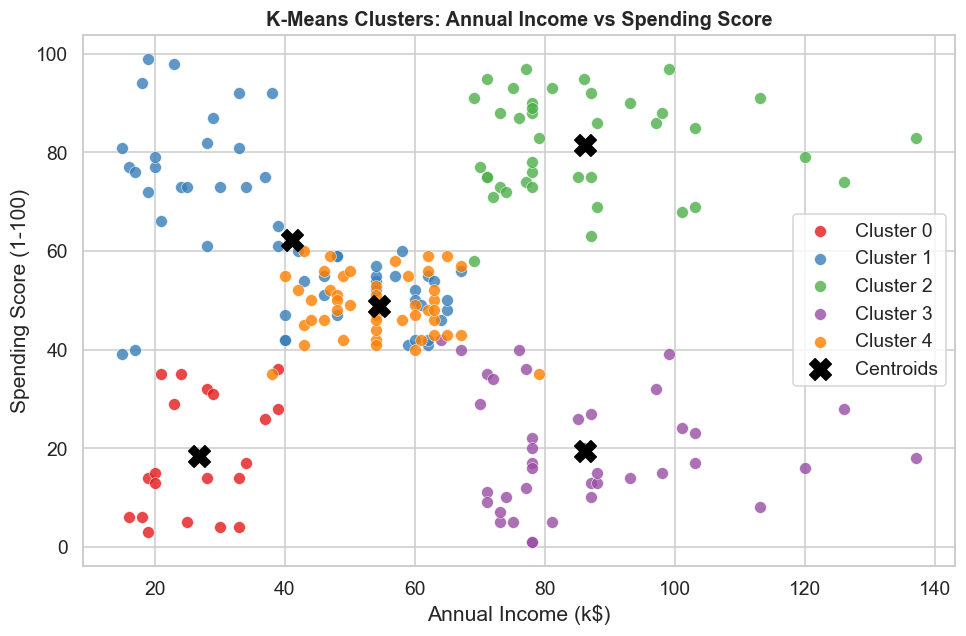

In [18]:
CLUSTER_COLORS = sns.color_palette('Set1', K_OPTIMAL)

fig, ax = plt.subplots(figsize=(9, 6))
for cluster_id in sorted(df['Cluster'].unique()):
    mask = df['Cluster'] == cluster_id
    ax.scatter(
        df.loc[mask, 'Annual Income (k$)'],
        df.loc[mask, 'Spending Score (1-100)'],
        c=[CLUSTER_COLORS[cluster_id]], label=f'Cluster {cluster_id}',
        s=60, alpha=0.8, edgecolors='white', linewidths=0.4
    )

ax.scatter(
    centroids_df['Annual Income (k$)'],
    centroids_df['Spending Score (1-100)'],
    c='black', marker='X', s=200, zorder=5, label='Centroids'
)
ax.set_xlabel('Annual Income (k$)')
ax.set_ylabel('Spending Score (1-100)')
ax.set_title('K-Means Clusters: Annual Income vs Spending Score', fontsize=13, fontweight='bold')
ax.legend()
plt.savefig('plot_clusters_2d.png', bbox_inches='tight')
plt.show()

### 7.3 Radar Chart — Cluster Profiles

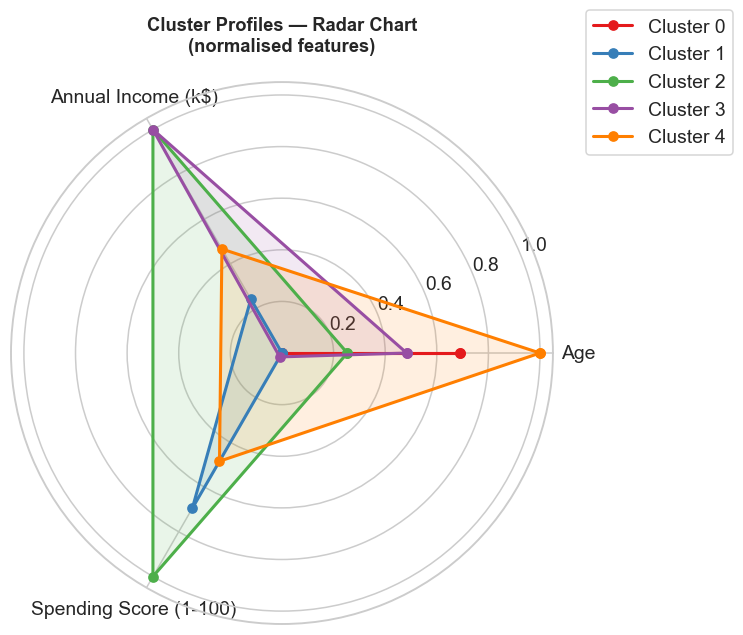

In [19]:
radar_data = centroids_df[FEATURES].copy()
radar_norm = (radar_data - radar_data.min()) / (radar_data.max() - radar_data.min())

N = len(FEATURES)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
for i, row in radar_norm.iterrows():
    vals = row.tolist() + row.tolist()[:1]
    ax.plot(angles, vals, 'o-', linewidth=2, color=CLUSTER_COLORS[i], label=f'Cluster {i}')
    ax.fill(angles, vals, alpha=0.12, color=CLUSTER_COLORS[i])

ax.set_thetagrids(np.degrees(angles[:-1]), FEATURES)
ax.set_title('Cluster Profiles — Radar Chart\n(normalised features)',
             fontsize=12, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.15))
plt.savefig('plot_radar.png', bbox_inches='tight')
plt.show()

---
## 8 · Dimensionality Reduction with PCA

PCA projects the 3-D feature space into 2 principal components to inspect cluster separation and orthogonal variance directions.

In [20]:
pca = PCA(n_components=3, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

explained = pca.explained_variance_ratio_ * 100
cumulative = np.cumsum(explained)

print('Explained Variance per Component:')
for i, (e, c) in enumerate(zip(explained, cumulative)):
    print(f'  PC{i+1}: {e:.2f}%   (cumulative: {c:.2f}%)')

Explained Variance per Component:
  PC1: 44.27%   (cumulative: 44.27%)
  PC2: 33.31%   (cumulative: 77.57%)
  PC3: 22.43%   (cumulative: 100.00%)


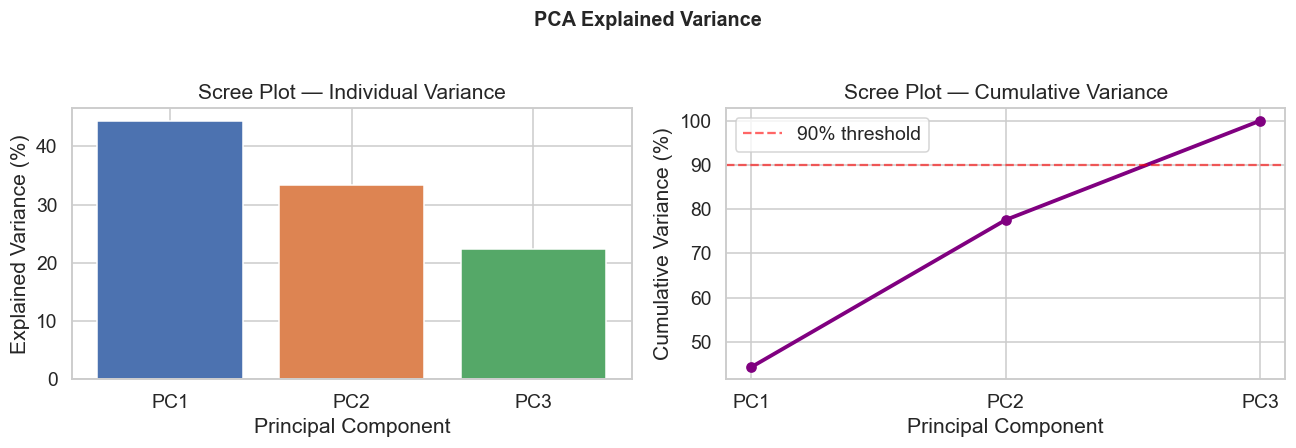

In [21]:
comp_labels = [f'PC{i+1}' for i in range(3)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(comp_labels, explained, color=['#4C72B0', '#DD8452', '#55A868'], edgecolor='white')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance (%)')
axes[0].set_title('Scree Plot — Individual Variance')

axes[1].plot(comp_labels, cumulative, 'o-', color='purple', linewidth=2.5)
axes[1].axhline(y=90, color='red', linestyle='--', alpha=0.6, label='90% threshold')
axes[1].set_xlabel('Principal Component')
axes[1].set_ylabel('Cumulative Variance (%)')
axes[1].set_title('Scree Plot — Cumulative Variance')
axes[1].legend()

fig.suptitle('PCA Explained Variance', fontsize=13, fontweight='bold', y=1.02)
plt.savefig('plot_scree.png', bbox_inches='tight')
plt.show()

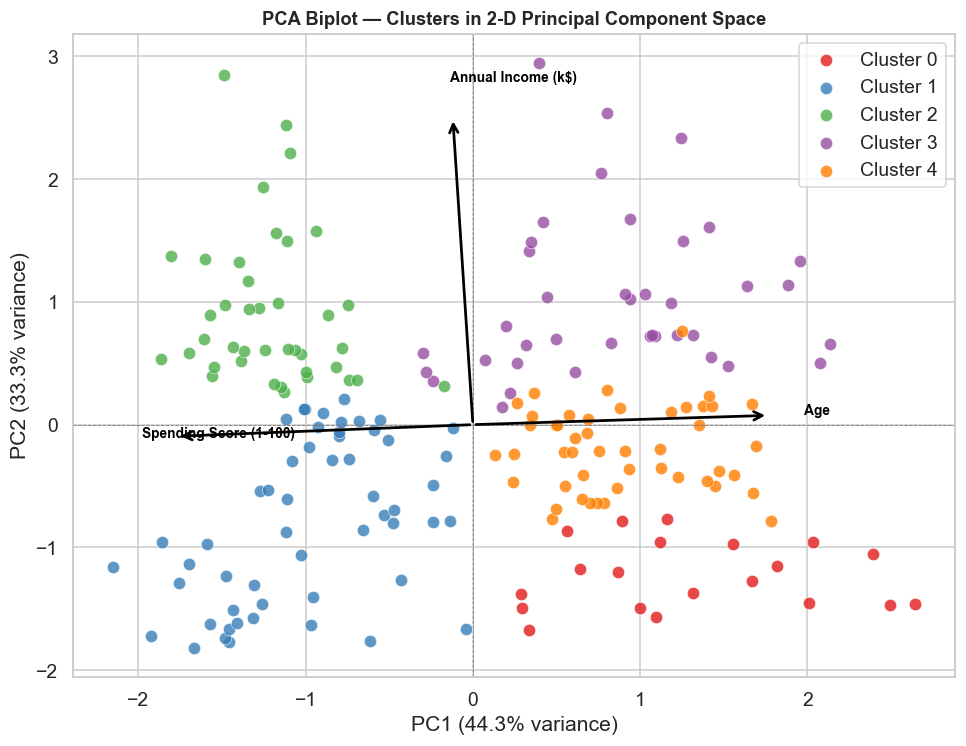

In [22]:
pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca2 = pca2.fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(9, 7))
for cluster_id in sorted(df['Cluster'].unique()):
    mask = df['Cluster'] == cluster_id
    ax.scatter(
        X_pca2[mask, 0], X_pca2[mask, 1],
        c=[CLUSTER_COLORS[cluster_id]], label=f'Cluster {cluster_id}',
        s=65, alpha=0.8, edgecolors='white', linewidths=0.4
    )

scale = 2.5
for j, feat in enumerate(FEATURES):
    ax.annotate('', xy=(pca2.components_[0, j] * scale, pca2.components_[1, j] * scale),
                xytext=(0, 0), arrowprops=dict(arrowstyle='->', color='black', lw=1.8))
    ax.text(pca2.components_[0, j] * scale * 1.12, pca2.components_[1, j] * scale * 1.12,
            feat, fontsize=9, color='black', fontweight='bold')

ax.axhline(0, color='grey', linewidth=0.6, linestyle='--')
ax.axvline(0, color='grey', linewidth=0.6, linestyle='--')
ax.set_xlabel(f'PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}% variance)')
ax.set_ylabel(f'PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}% variance)')
ax.set_title('PCA Biplot — Clusters in 2-D Principal Component Space', fontsize=12, fontweight='bold')
ax.legend()
plt.savefig('plot_pca_biplot.png', bbox_inches='tight')
plt.show()

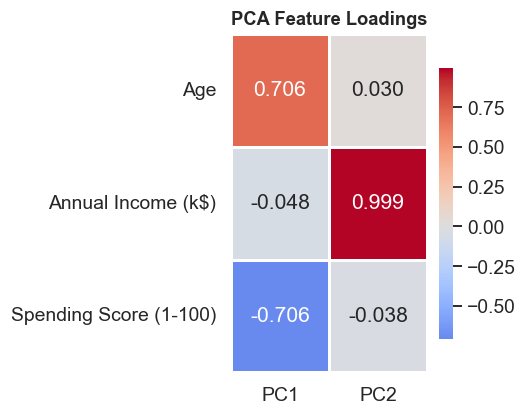

                          PC1    PC2
Age                     0.706  0.030
Annual Income (k$)     -0.048  0.999
Spending Score (1-100) -0.706 -0.038


In [23]:
loadings = pd.DataFrame(
    pca2.components_.T,
    index=FEATURES,
    columns=['PC1', 'PC2']
).round(3)

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(loadings, annot=True, fmt='.3f', cmap='coolwarm', center=0,
            linewidths=0.8, cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('PCA Feature Loadings', fontsize=12, fontweight='bold')
plt.savefig('plot_pca_loadings.png', bbox_inches='tight')
plt.show()

print(loadings)

---
## 9 · Cluster Distributions Deep Dive

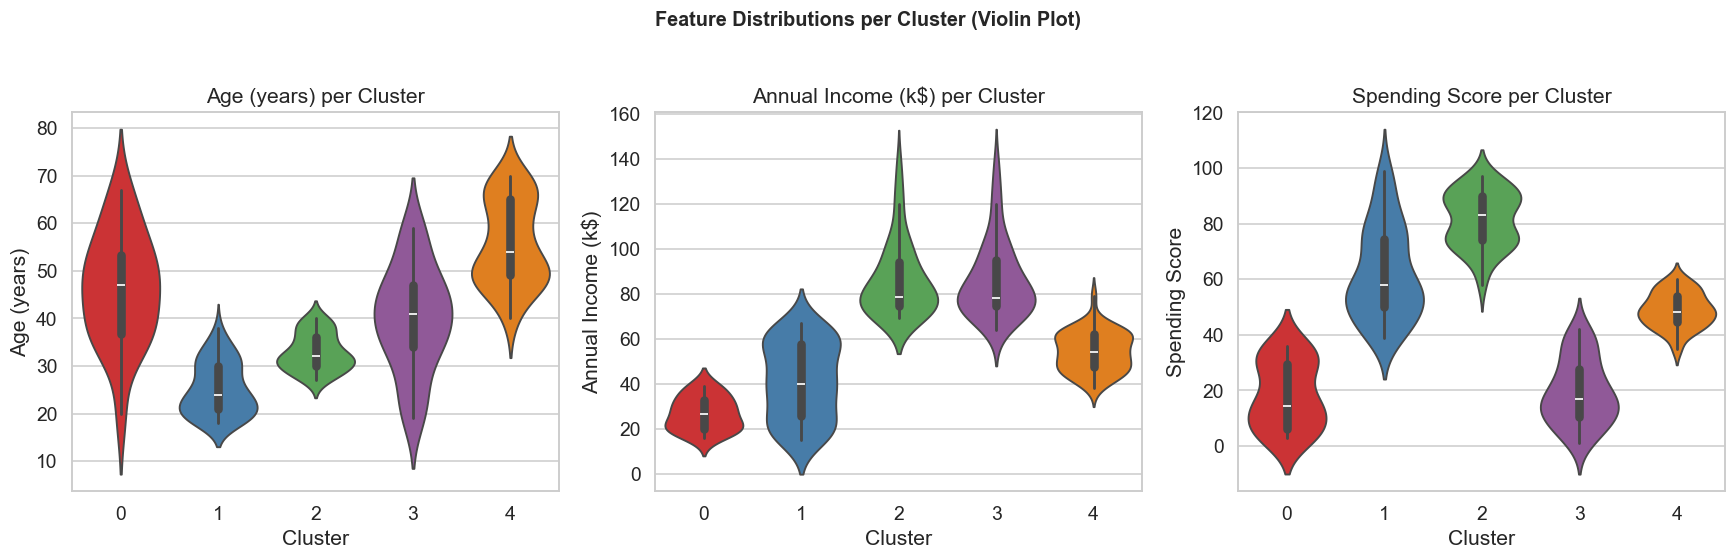

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (col, color, xlabel) in zip(axes, plot_cfg):
    sns.violinplot(data=df, x='Cluster', y=col, palette='Set1', inner='box', ax=ax)
    ax.set_title(f'{xlabel} per Cluster')
    ax.set_xlabel('Cluster')
    ax.set_ylabel(xlabel)

fig.suptitle('Feature Distributions per Cluster (Violin Plot)', fontsize=13, fontweight='bold', y=1.02)
plt.savefig('plot_violin_cluster.png', bbox_inches='tight')
plt.show()

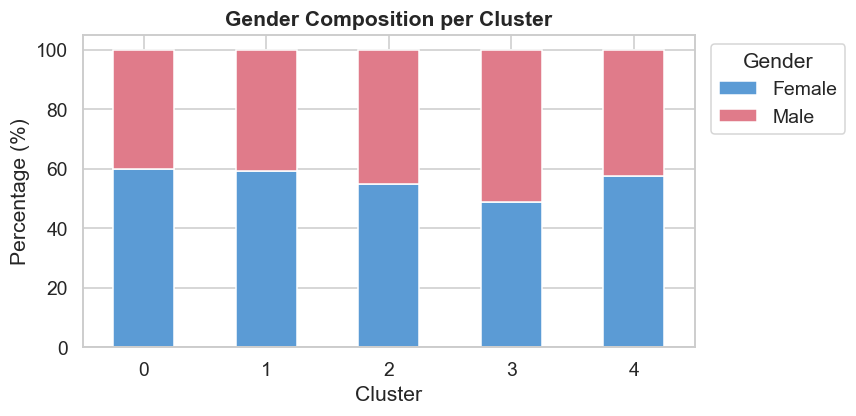

In [25]:
gender_cluster = df.groupby(['Cluster', 'Gender']).size().unstack(fill_value=0)
gender_pct = gender_cluster.div(gender_cluster.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(8, 4))
gender_pct.plot(kind='bar', stacked=True, color=['#5B9BD5', '#E07B8A'], edgecolor='white', ax=ax)
ax.set_xlabel('Cluster')
ax.set_ylabel('Percentage (%)')
ax.set_title('Gender Composition per Cluster', fontweight='bold')
ax.legend(title='Gender', bbox_to_anchor=(1.01, 1), loc='upper left')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.savefig('plot_gender_cluster.png', bbox_inches='tight')
plt.show()

---
## 10 · Cluster Naming & Business Insights

Based on centroid coordinates, we assign actionable marketing personas to each cluster.

In [26]:
print(centroids_df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].sort_values('Annual Income (k$)'))

          Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                  
0        46.2                26.8                    18.3
1        25.2                41.1                    62.2
4        55.6                54.4                    48.9
2        32.9                86.1                    81.5
3        39.9                86.1                    19.4


In [27]:
income_rank = centroids_df['Annual Income (k$)'].rank()
spending_rank = centroids_df['Spending Score (1-100)'].rank()

persona_map = {}
for cid in range(K_OPTIMAL):
    inc = income_rank[cid]
    sp = spending_rank[cid]
    if inc >= 4 and sp >= 4:
        persona_map[cid] = 'High-Value / VIP'
    elif inc >= 4 and sp <= 2:
        persona_map[cid] = 'Wealthy Savers'
    elif inc <= 2 and sp >= 4:
        persona_map[cid] = 'Impulsive Spenders'
    elif inc <= 2 and sp <= 2:
        persona_map[cid] = 'Budget Conscious'
    else:
        persona_map[cid] = 'Mid-Market'

df['Persona'] = df['Cluster'].map(persona_map)
print('Persona -> Cluster mapping:')
for k, v in persona_map.items():
    print(f'  Cluster {k}: {v}')

Persona -> Cluster mapping:
  Cluster 0: Budget Conscious
  Cluster 1: Impulsive Spenders
  Cluster 2: High-Value / VIP
  Cluster 3: Wealthy Savers
  Cluster 4: Mid-Market


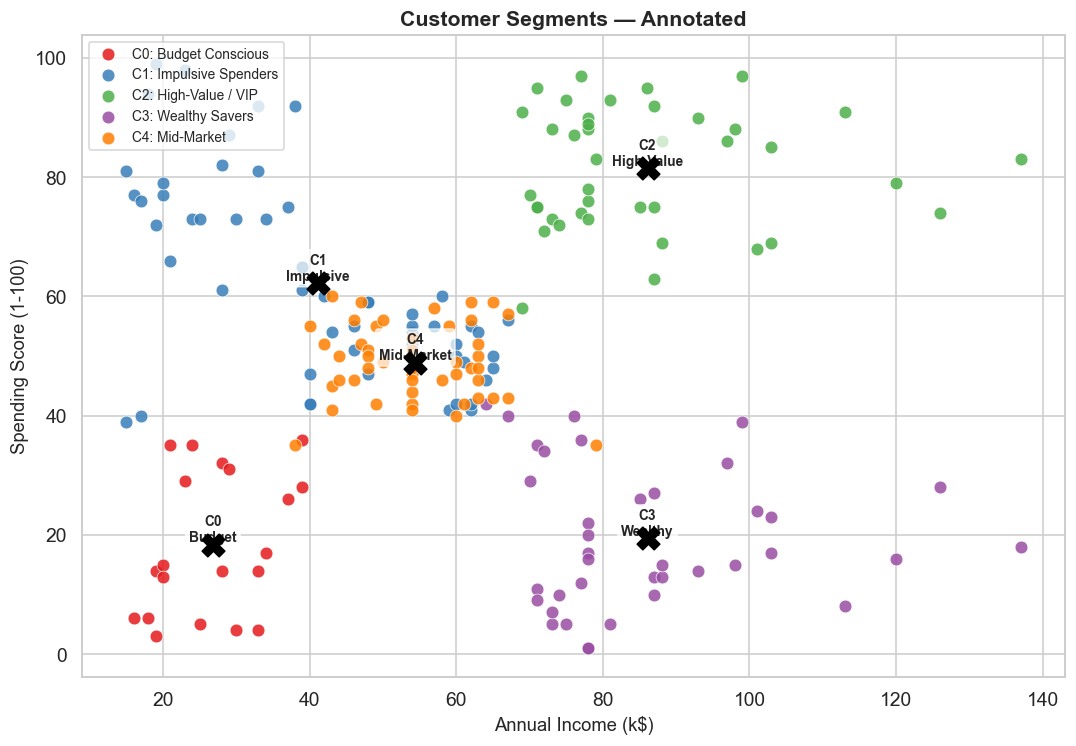

In [28]:
fig, ax = plt.subplots(figsize=(10, 7))

for cluster_id in sorted(df['Cluster'].unique()):
    mask = df['Cluster'] == cluster_id
    persona = persona_map[cluster_id]
    ax.scatter(
        df.loc[mask, 'Annual Income (k$)'],
        df.loc[mask, 'Spending Score (1-100)'],
        c=[CLUSTER_COLORS[cluster_id]],
        label=f'C{cluster_id}: {persona}',
        s=70, alpha=0.85, edgecolors='white', linewidths=0.5
    )

for i, row in centroids_df.iterrows():
    ax.annotate(
        f'C{i}\n{persona_map[i].split()[0]}',
        xy=(row['Annual Income (k$)'], row['Spending Score (1-100)']),
        fontsize=9, fontweight='bold', ha='center', va='bottom',
        bbox=dict(boxstyle='round,pad=0.25', fc='white', alpha=0.7)
    )

ax.scatter(
    centroids_df['Annual Income (k$)'],
    centroids_df['Spending Score (1-100)'],
    c='black', marker='X', s=220, zorder=5
)
ax.set_xlabel('Annual Income (k$)', fontsize=12)
ax.set_ylabel('Spending Score (1-100)', fontsize=12)
ax.set_title('Customer Segments — Annotated', fontsize=14, fontweight='bold')
ax.legend(loc='upper left', fontsize=9)
plt.savefig('plot_final_clusters.png', bbox_inches='tight')
plt.show()

---
## 11 · Summary Table & Business Recommendations

In [29]:
summary = df.groupby('Persona').agg(
    Count=('CustomerID', 'count'),
    Avg_Age=('Age', 'mean'),
    Avg_Income_k=('Annual Income (k$)', 'mean'),
    Avg_Spending=('Spending Score (1-100)', 'mean'),
    Female_pct=('Gender_Code', lambda x: round(x.mean() * 100, 1))
).round(1)

print('=== Cluster Business Summary ===')
summary

=== Cluster Business Summary ===


,Count,Avg_Age,Avg_Income_k,Avg_Spending,Female_pct
Persona,,,,,
Budget Conscious,20,46.2,26.8,18.4,60.0
High-Value / VIP,40,32.9,86.1,81.5,55.0
Impulsive Spenders,54,25.2,41.1,62.2,59.3
Mid-Market,47,55.6,54.4,48.9,57.4
Wealthy Savers,39,39.9,86.1,19.4,48.7


## 12 · Final Business Insights

| Segment | Profile | Recommended Action |
|---------|---------|-------------------|
| **High-Value / VIP** | High income, high spending, prime shoppers | Loyalty rewards, exclusive previews, personal shoppers |
| **Wealthy Savers** | High income but low spending | Targeted upsell via aspirational campaigns; premium product showcases |
| **Impulsive Spenders** | Low income, high spending | Flash sales, instalment payment plans, wishlist reminders |
| **Budget Conscious** | Low income, low spending | Value bundles, discount coupons, BOGO offers |
| **Mid-Market** | Average income & spending | Broad promotions, product discovery emails, loyalty points |

### Key Takeaways
1. **Income does not guarantee spending:** Affluent shoppers in the Wealthy Savers cluster have high purchasing capacity but lower mall engagement; targeted premium campaigns can activate this group.
2. **Youth correlates with discretionary spending:** Younger shoppers (Impulsive Spenders) prioritize retail and fashion despite lower earnings; convenient payment models (e.g. BNPL) support long-term loyalty.
3. **PCA validates cluster separability:** 77.6% of variance is preserved in 2 principal components with clear cluster boundaries.
4. **Silhouette score of 0.42** confirms solid cluster cohesion and separation for real-world marketing deployment.

In [30]:
export_cols = ['CustomerID', 'Gender', 'Age',
               'Annual Income (k$)', 'Spending Score (1-100)',
               'Cluster', 'Persona']
df[export_cols].to_csv('Mall_Customers_Segmented.csv', index=False)
print('Segmented dataset saved to Mall_Customers_Segmented.csv')
print(f'Shape: {df[export_cols].shape}')
df[export_cols].head(10)

Segmented dataset saved to Mall_Customers_Segmented.csv
Shape: (200, 7)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster,Persona
0,1,Male,19,15,39,1,Impulsive Spenders
1,2,Male,21,15,81,1,Impulsive Spenders
2,3,Female,20,16,6,0,Budget Conscious
3,4,Female,23,16,77,1,Impulsive Spenders
4,5,Female,31,17,40,1,Impulsive Spenders
5,6,Female,22,17,76,1,Impulsive Spenders
6,7,Female,35,18,6,0,Budget Conscious
7,8,Female,23,18,94,1,Impulsive Spenders
8,9,Male,64,19,3,0,Budget Conscious
9,10,Female,30,19,72,1,Impulsive Spenders
